Cell 1 — Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


Cell 2 — Read CSV

In [2]:
df = pd.read_csv("bank.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


Cell 3 — Understand the data

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'deposit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11162 non-null  int64 
 1   job        11162 non-null  object
 2   marital    11162 non-null  object
 3   education  11162 non-null  object
 4   default    11162 non-null  object
 5   balance    11162 non-null  int64 
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11162 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11162 non-null  int64 
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   1

Cell 4 — Check target distribution

yes = Customer subscribed.



no = Customer did not subscribe.

In [4]:
target = "deposit" if "deposit" in df.columns else "y"

print("Target column:", target)
print(df[target].value_counts())

Target column: deposit
deposit
no     5873
yes    5289
Name: count, dtype: int64


Visualize the data


Cell 5 — Target distribution

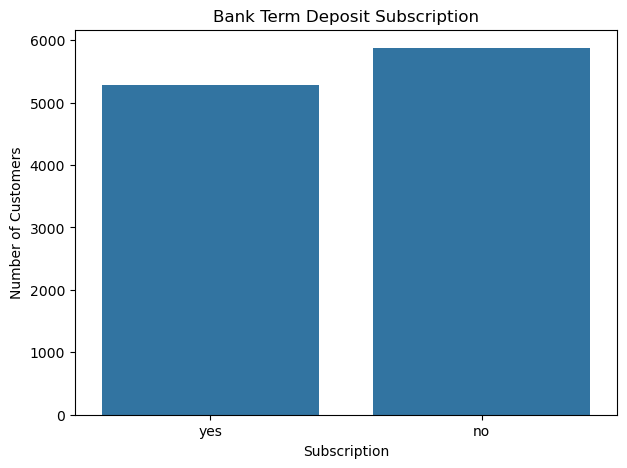

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x=target)

plt.title("Bank Term Deposit Subscription")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.show()

Cell 6 — Customer age distribution

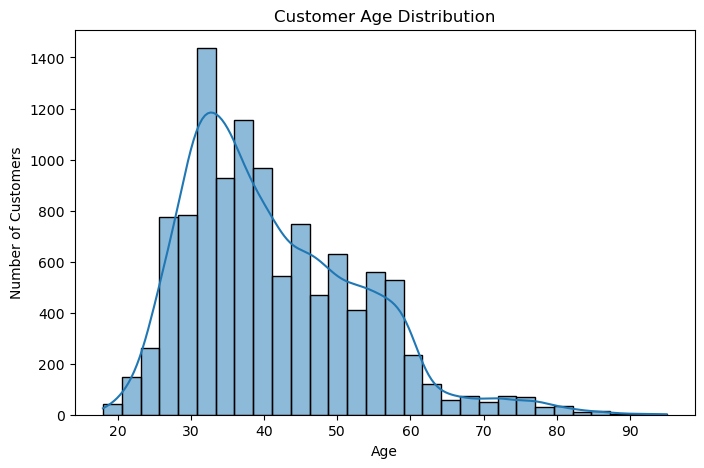

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

Cell 7 — Separate features and target

In [7]:
X = df.drop(columns=[target])
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.unique())

Features shape: (11162, 16)
Target shape: (11162,)

Target classes:
['yes' 'no']


Cell 8 — Identify categorical and numerical columns

In [8]:
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("\nNumerical columns:", numerical_columns)

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical columns: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


Important: We will remove the duration feature if it exists. Call duration is only known after a marketing call, so using it would make a real pre-call prediction unrealistic.

In [9]:
if "duration" in X.columns:
    X = X.drop(columns=["duration"])

categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Features after preprocessing:", X.shape[1])

Features after preprocessing: 15


Cell 9 — Train-test split

We use 80% of the data for training and 20% for testing.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8929
Testing samples: 2233


Build and train the Decision Tree model


Cell 10 — Preprocessing and model training

In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_columns)
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Simple explanation:
- OneHotEncoder converts categorical data into numerical columns.
- DecisionTreeClassifier learns rules from the data.
- max_depth=5 limits tree depth to help control overfitting.
- class_weight="balanced" helps account for unequal class counts.

Test the model


Cell 11 — Make predictions

In [12]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 68.56%


Evaluate the model


Cell 12 — Classification report

In [13]:
print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

          no       0.67      0.79      0.73      1175
         yes       0.71      0.56      0.63      1058

    accuracy                           0.69      2233
   macro avg       0.69      0.68      0.68      2233
weighted avg       0.69      0.69      0.68      2233



Cell 13 — Confusion matrix

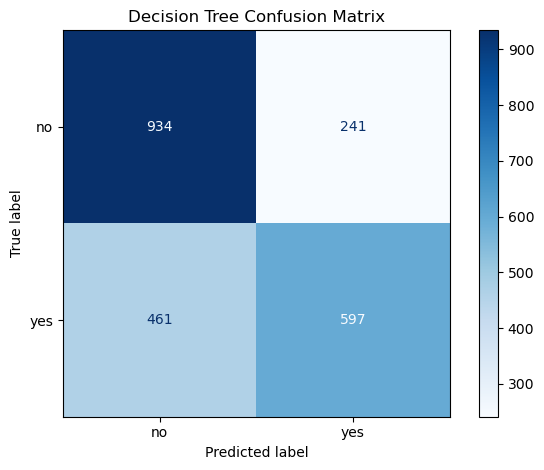

In [14]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot(cmap="Blues")
plt.title("Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

Visualize the Decision Tree


Cell 14 — Plot the tree

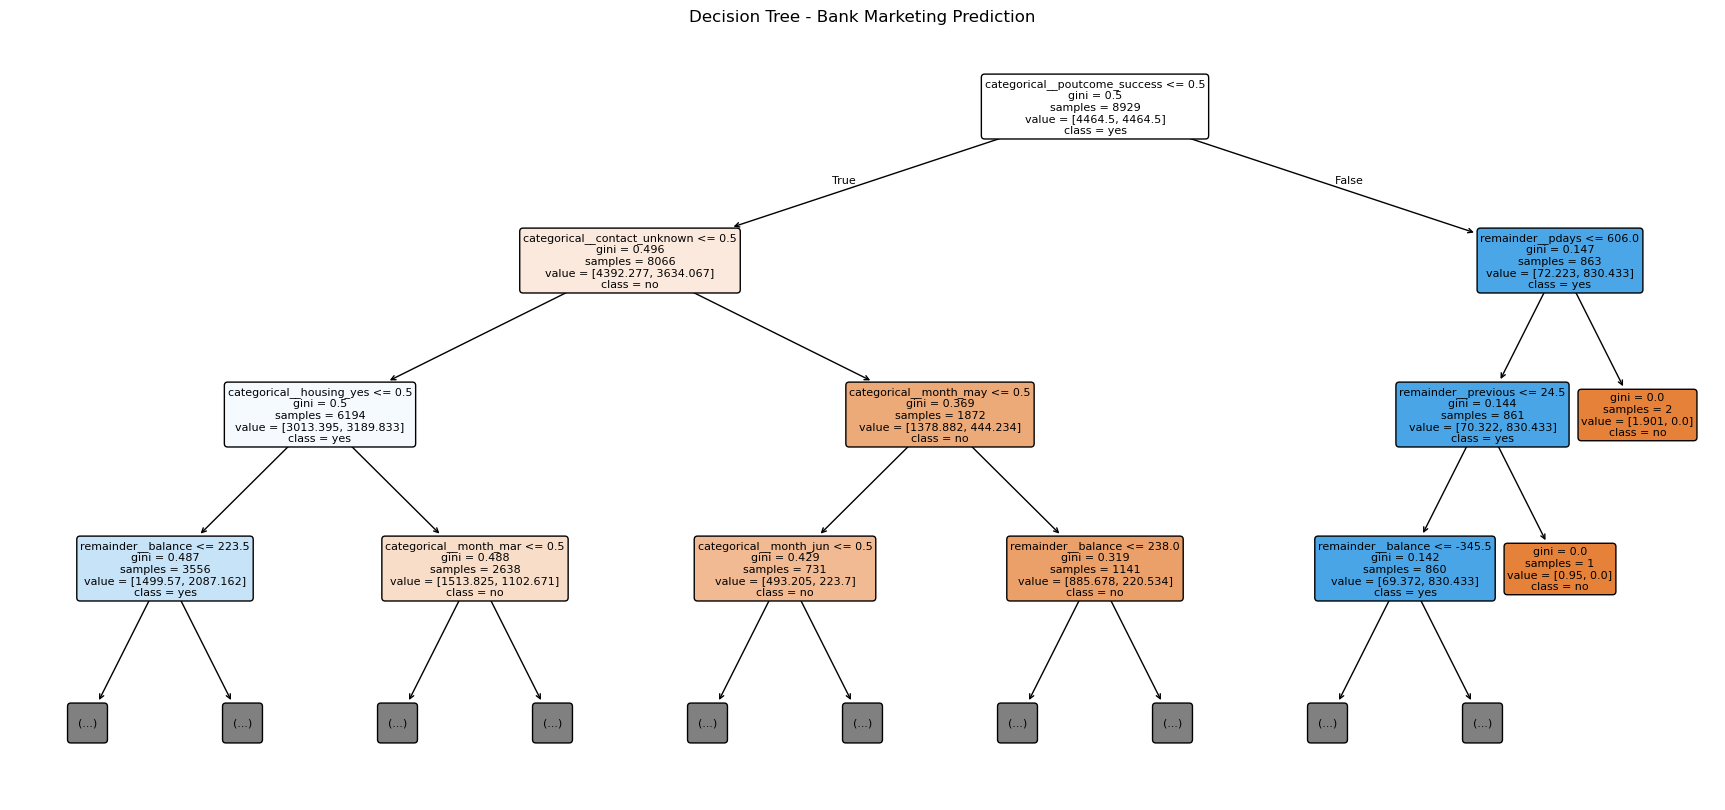

In [15]:
plt.figure(figsize=(22, 10))

tree_model = model.named_steps["classifier"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[str(c) for c in tree_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree - Bank Marketing Prediction")
plt.show()

This graph shows how the Decision Tree makes decisions based on customer information.

This graph shows how the Decision Tree makes decisions based on customer information.

Test one customer prediction


Cell 15 — Predict using a test example

In [16]:
sample = X_test.iloc[[0]]

prediction = model.predict(sample)[0]
actual = y_test.iloc[0]

print("Predicted result:", prediction)
print("Actual result:", actual)

if prediction == actual:
    print("Prediction is correct!")
else:
    print("Prediction is incorrect.")

Predicted result: yes
Actual result: no
Prediction is incorrect.


Save the trained model


Cell 16 — Save model

In [17]:
import os

os.makedirs("outputs", exist_ok=True)

joblib.dump(
    model,
    "outputs/bank_marketing_decision_tree.pkl"
)

print("Model saved successfully!")

Model saved successfully!


## Conclusion

In this project, I used a Decision Tree algorithm to predict whether a customer would subscribe to a bank deposit. I prepared the data, trained the model, and tested its performance. This helped me understand how Decision Trees work for classification.